# Week 5 — Additional Models
- Try Decision Tree and Random Forest regressors.
- Compare their test R² against baseline.
- Document model behavior (strengths/weaknesses).


*Baseline Model (Linear Regression) results:*

--- Validation Set - OLS Evaluation Metrics ---

R² Score : 0.7438

MAE      : $294,942.96

MAPE     : 25.93%

MdAPE    : 19.76%

--- Test Set - OLS Evaluation Metrics ---

R² Score : 0.7573

MAE      : $298,593.64

MAPE     : 25.76%

MdAPE    : 19.63%

# Setup

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.impute import SimpleImputer


# Validation
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

In [ ]:
filtered_cleaned = pd.read_csv("/content/drive/MyDrive/IDX Data Science/filtered_cleaned.csv")
print(f"Current number of rows: {len(filtered_cleaned)}")

/tmp/ipykernel_1228/2430598771.py:1: DtypeWarning: Columns (0,1,4,64,74,79,81,82,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  filtered_cleaned = pd.read_csv("/content/drive/MyDrive/IDX Data Science/filtered_cleaned.csv")


Current number of rows: 303800


In [ ]:
test = filtered_cleaned[filtered_cleaned['FileDate'] == '2026-04-01']
print(f"Test set size: {len(test)}")
validation = filtered_cleaned[filtered_cleaned['FileDate'] == '2026-03-01']
print(f"Validation set size: {len(validation)}")
train = filtered_cleaned[filtered_cleaned['FileDate'] < '2026-03-01']
print(f"Train set size: {len(train)}")

print(f"Total Rows Check: {len(test) + len(validation) + len(train)}")

Test set size: 12225
Validation set size: 11368
Train set size: 280207
Total Rows Check: 303800


In [ ]:
# set outlier cutoffs based on the training set
lower_bound = train['ClosePrice'].quantile(0.05)
upper_bound = train['ClosePrice'].quantile(0.995)
print(f"Lower bound: {lower_bound}")
print(f"Upper bound: {upper_bound}")

Lower bound: 365000.0
Upper bound: 8300000.0


In [ ]:
key_feature_cols = ['LivingArea', 'BedroomsTotal',
                    'BathroomsTotalInteger', 'LotSizeSquareFeet',
                    'YearBuilt', 'Latitude', 'Longitude', 'City',
                    #added from other members
                    'Stories', 'CountyOrParish']

# filter based on upper and lower bounds from training
train = train[(train['ClosePrice'] > lower_bound) & (train['ClosePrice'] < upper_bound)]
validation = validation[(validation['ClosePrice'] > lower_bound) & (validation['ClosePrice'] < upper_bound)]
test = test[(test['ClosePrice'] > lower_bound) & (test['ClosePrice'] < upper_bound)]

#keep feature columns
train = train[key_feature_cols + ['ClosePrice']]
validation = validation[key_feature_cols + ['ClosePrice']]
test = test[key_feature_cols + ['ClosePrice']]

In [ ]:
# Row counts after removing outliers
print(f"Test set size: {len(test)}")
print(f"Validation set size: {len(validation)}")
print(f"Train set size: {len(train)}")

print(f"Total Rows: {len(test) + len(validation) + len(train)}")

Test set size: 11519
Validation set size: 10681
Train set size: 264737
Total Rows: 286937


In [ ]:
# separate X's and Y for data sets
Y_train = train['ClosePrice']
X_train = train[key_feature_cols]

Y_val = validation['ClosePrice']
X_val = validation[key_feature_cols]

Y_test = test['ClosePrice']
X_test = test[key_feature_cols]

In [ ]:
cat_cols = ['City', 'CountyOrParish']
num_cols = ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Latitude', 'Longitude', 'Stories']

In [ ]:
cat_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", TargetEncoder()),
    ]
)

num_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
    ]
)


In [ ]:
# MdAPE
def median_absolute_percentage_error(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true)) * 100
# function to evaluate different errors (R^2, MAE, MAPE, MdAPE)
def evaluate_predictions(y_true, y_pred, split_name="Validation"):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100  # Convert ratio to %
    mdape = median_absolute_percentage_error(y_true, y_pred)

    print(f"--- {split_name} Evaluation Metrics ---")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : ${mae:,.2f}")
    print(f"MAPE     : {mape:.2f}%")
    print(f"MdAPE    : {mdape:.2f}%\n")

## Decision Tree

In [ ]:
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor())
])
dt_pipeline.fit(X_train, Y_train)
dt_val_preds = dt_pipeline.predict(X_val)
evaluate_predictions(Y_val, dt_val_preds, split_name="Validation Set - Decision Tree")

--- Validation Set - Decision Tree Evaluation Metrics ---
R² Score : 0.7916
MAE      : $214,305.92
MAPE     : 15.35%
MdAPE    : 10.03%



In [ ]:
# Testing on combined data X_train and X_val
X_train_val = pd.concat([X_train, X_val], axis=0)
Y_train_val = pd.concat([Y_train, Y_val], axis=0)

dt_pipeline.fit(X_train_val, Y_train_val)

# Predict on held-out test set
dt_test_preds = dt_pipeline.predict(X_test)
evaluate_predictions(Y_test, dt_test_preds, split_name="Test Set - Decision Tree")

--- Test Set - Decision Tree Evaluation Metrics ---
R² Score : 0.7849
MAE      : $222,519.74
MAPE     : 15.33%
MdAPE    : 10.00%



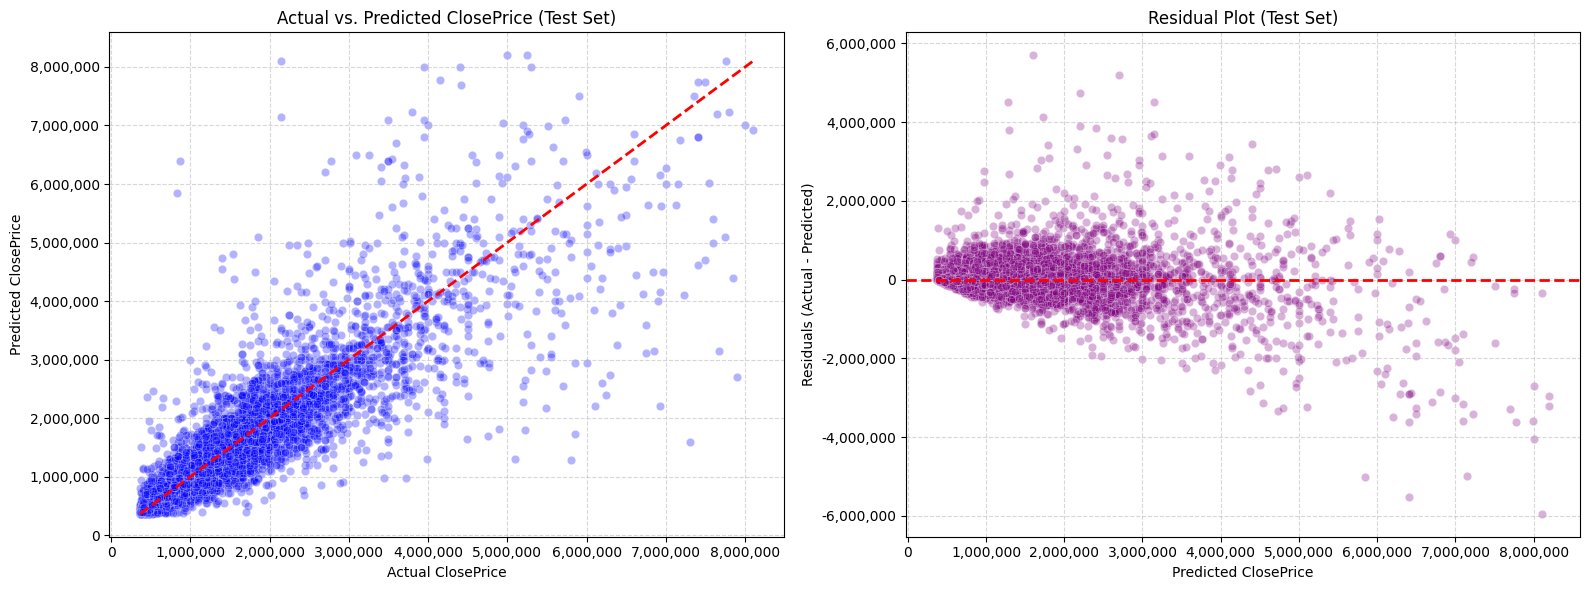

In [ ]:
# Calculate residuals
residuals = Y_test - dt_test_preds

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs. Predicted
sns.scatterplot(x=Y_test, y=dt_test_preds, alpha=0.3, ax=axes[0], color='blue')
axes[0].plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted ClosePrice (Test Set)')
axes[0].set_xlabel('Actual ClosePrice')
axes[0].set_ylabel('Predicted ClosePrice')
axes[0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Residual Plot
sns.scatterplot(x=dt_test_preds, y=residuals, alpha=0.3, ax=axes[1], color='purple')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_title('Residual Plot (Test Set)')
axes[1].set_xlabel('Predicted ClosePrice')
axes[1].set_ylabel('Residuals (Actual - Predicted)')
axes[1].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Random Forest

In [ ]:
# Gemini-Assisted: Optimized Random Forest configuration for 280k+ rows to help with runtime issues
rf_fast = RandomForestRegressor(
    n_estimators=100,      # 100 trees is sufficient for most datasets
    max_depth=15,          # CRITICAL: Prevents trees from growing infinitely deep
    max_samples=0.2,       # CRITICAL: Fits each tree on a 20% random sample (~56k rows)
    max_features="sqrt",   # Limits feature search per split to decorrelate trees
    min_samples_leaf=5,    # Stops splitting small noisy leaves early
    n_jobs=-1,             # CRITICAL: Uses ALL CPU cores in parallel
    random_state=42
)

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', rf_fast)
])
rf_pipeline.fit(X_train, Y_train)
rf_val_preds = rf_pipeline.predict(X_val)
evaluate_predictions(Y_val, rf_val_preds, split_name="Validation Set - Random Forest")

--- Validation Set - Random Forest Evaluation Metrics ---
R² Score : 0.8557
MAE      : $183,694.14
MAPE     : 13.13%
MdAPE    : 8.95%



In [ ]:
rf_pipeline.fit(X_train_val, Y_train_val)

# Predict on held-out test set
rf_test_preds = rf_pipeline.predict(X_test)
evaluate_predictions(Y_test, rf_test_preds, split_name="Test Set - Random Forest")

--- Test Set - Random Forest Evaluation Metrics ---
R² Score : 0.8598
MAE      : $188,239.03
MAPE     : 13.27%
MdAPE    : 9.07%



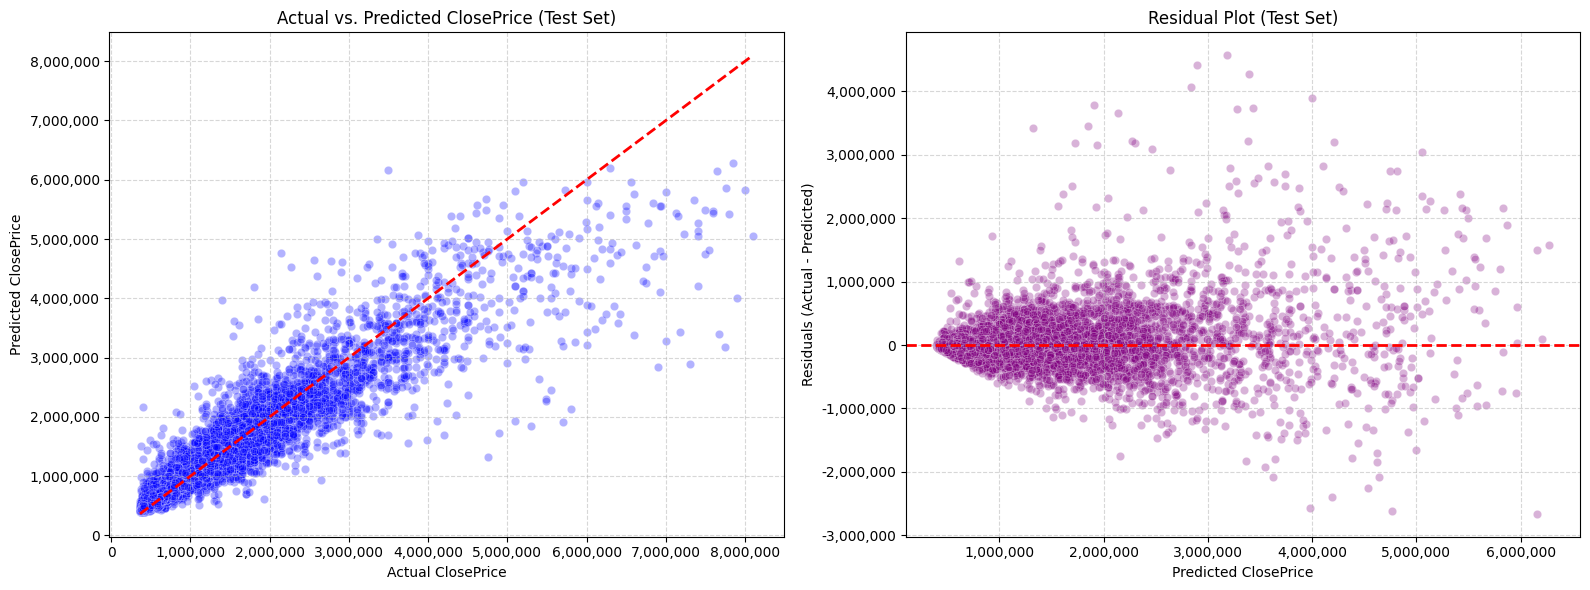

In [ ]:
# Calculate residuals
residuals_rf = Y_test - rf_test_preds

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs. Predicted
sns.scatterplot(x=Y_test, y=rf_test_preds, alpha=0.3, ax=axes[0], color='blue')
axes[0].plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted ClosePrice (Test Set)')
axes[0].set_xlabel('Actual ClosePrice')
axes[0].set_ylabel('Predicted ClosePrice')
axes[0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Residual Plot
sns.scatterplot(x=rf_test_preds, y=residuals_rf, alpha=0.3, ax=axes[1], color='purple')
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_title('Residual Plot (Test Set)')
axes[1].set_xlabel('Predicted ClosePrice')
axes[1].set_ylabel('Residuals (Actual - Predicted)')
axes[1].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Overall, these models performed significantly better than the baseline Linear Regression model.

### Model Comparison

In [ ]:
metrics_data = {
    "Metric": ["R² Score", "Mean Absolute Error (MAE)", "MAPE", "MdAPE"],
    "Linear Regression (Baseline)": [0.7573, "$298,593.64", "25.76%", "19.63%"],
    "Decision Tree": [0.7916, "$221,783.62", "15.32%", "9.93%"],
    "Random Forest (Optimized)": [0.8598, "$188,095.21", "13.24%", "9.01%"]
}

summary_df = pd.DataFrame(metrics_data).set_index("Metric")
display(summary_df)

,Linear Regression (Baseline),Decision Tree,Random Forest (Optimized)
Metric,,,
R² Score,0.7573,0.7916,0.8598
Mean Absolute Error (MAE),"$298,593.64","$221,783.62","$188,095.21"
MAPE,25.76%,15.32%,13.24%
MdAPE,19.63%,9.93%,9.01%


The Random Forest model performed the best on all metrics, with the most significant increase in R^2. Otherwise, the Decision Tree only performs slightly worse for MAE, MAPE, and MdAPE and still performs better than the baseline model.

# Feature Engineering (Week 6)

In [ ]:
# operate on new copy
fe_data = filtered_cleaned.copy()

In [ ]:
# creating new numerical columns
fe_data['BedBathRatio'] = fe_data['BedroomsTotal'] / fe_data['BathroomsTotalInteger']
fe_data['LotAreaRatio'] = fe_data['LotSizeSquareFeet'] / fe_data['LivingArea']
fe_data['AgeOfProperty'] = fe_data['YearBuilt'].apply(lambda x: 2026 - x)
fe_data['RelativeSize'] = fe_data['LivingArea'] / fe_data.groupby('CountyOrParish')['LivingArea'].transform('median')


In [ ]:
import geopandas as gpd
## geographic encoding

districts_gdf = gpd.read_file("zip:///content/drive/MyDrive/IDX Data Analyst/Datasets/DistrictAreas2526_6284572545507999242.zip")

In [42]:
import os
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

# Convert coordinates to Shapely Point geometries (WGS84 / EPSG:4326)
geometry = [Point(xy) for xy in zip(fe_data["Longitude"], fe_data["Latitude"])]
properties_gdf = gpd.GeoDataFrame(fe_data, geometry=geometry, crs="EPSG:4326")

# read zipped shapefile
print("Loading school district shapefile...")
districts_gdf = gpd.read_file("zip:///content/drive/MyDrive/IDX Data Analyst/Datasets/DistrictAreas2526_6284572545507999242.zip")

# ==========================================
# 3. Align Coordinate Reference Systems (CRS)
# ==========================================
# Ensure both spatial layers share the exact same Coordinate Reference System
if properties_gdf.crs != districts_gdf.crs:
    print(f"Reprojecting districts CRS from {districts_gdf.crs} to {properties_gdf.crs}...")
    districts_gdf = districts_gdf.to_crs(properties_gdf.crs)

# ==========================================
# 4. Point-in-Polygon Spatial Join
# ==========================================
# Identify relevant district boundary columns (using correct column names from districts_gdf)
# 'DistrictNa' mapped to 'DistrictName', etc.
district_columns = [col for col in ["DistrictNa", "CDCode", "DistrictTy", "geometry"] if col in districts_gdf.columns]

print("Performing spatial join...")
joined_gdf = gpd.sjoin(
    properties_gdf,
    districts_gdf[district_columns],
    how="left",
    predicate="within",  # Assigns district features where the property point falls inside
)

# ==========================================
# 5. Clean & Handle Unmatched Points
# ==========================================
# Drop spatial index and geometry columns to convert back to a standard pandas DataFrame
df_with_districts = pd.DataFrame(
    joined_gdf.drop(columns=["geometry", "index_right"], errors="ignore")
)

# Rename columns to standardized names expected downstream
rename_dict = {
    "DistrictNa": "DistrictName",
    "DistrictTy": "DistrictType",
    "CDCode": "DistrictCode"
}
df_with_districts = df_with_districts.rename(columns=rename_dict)

# Fill properties outside mapped boundaries (e.g., coastal borders or unincorporated gaps)
if "DistrictName" in df_with_districts.columns:
    df_with_districts["DistrictName"] = df_with_districts["DistrictName"].fillna("Unassigned")

print(f"Successfully joined {len(df_with_districts)} properties with school district features!")

Loading school district shapefile...
Reprojecting districts CRS from EPSG:3857 to EPSG:4326...
Performing spatial join...
Successfully joined 379338 properties with school district features!


In [44]:
print("Available columns in districts_gdf:")
print(districts_gdf.columns)

print("\nFirst few rows of districts_gdf:")
display(districts_gdf.head())


Available columns in districts_gdf:
Index(['Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName', 'DistrictNa',
       'DistrictTy', 'GradeLow', 'GradeHigh', 'GradeLowCe', 'GradeHighC',
       'AssistStat', 'UpdateNote', 'EnrollTota', 'EnrollChar', 'EnrollNonC',
       'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount', 'ASpct', 'FIcount',
       'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct', 'WHcount', 'WHpct',
       'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount', 'ELpct', 'FOScount',
       'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount', 'MIGpct', 'SWDcount',
       'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAre', 'LocaleCode',
       'LocaleDesc', 'geometry'],
      dtype='object')

First few rows of districts_gdf:


,Year,FedID,CDCode,CDSCode,CountyName,DistrictNa,DistrictTy,GradeLow,GradeHigh,GradeLowCe,...,MIGcount,MIGpct,SWDcount,SWDpct,SEDcount,SEDpct,DistrctAre,LocaleCode,LocaleDesc,geometry
0,2025-26,0601770,0161119,01611190000000,Alameda,Alameda Unified,Unified,PK,12,KG,...,0,0.0,1302,12.1,4259,39.5,11.248886,21,"21 - Suburban, Large","MULTIPOLYGON (((-122.22678 37.72651, -122.2267..."
1,2025-26,0601860,0161127,01611270000000,Alameda,Albany City Unified,Unified,PK,12,KG,...,0,0.0,363,9.7,1247,33.3,1.789975,21,"21 - Suburban, Large","POLYGON ((-122.28671 37.89852, -122.28673 37.8..."
2,2025-26,0604740,0161143,01611430000000,Alameda,Berkeley Unified,Unified,PK,12,KG,...,0,0.0,1118,11.9,2710,28.8,10.434281,12,"12 - City, Midsize","POLYGON ((-122.25606 37.89834, -122.25607 37.8..."
3,2025-26,0607800,0161150,01611500000000,Alameda,Castro Valley Unified,Unified,PK,12,KG,...,2,0.0,1186,12.2,3784,39.0,66.885261,21,"21 - Suburban, Large","MULTIPOLYGON (((-122.01375 37.64265, -122.0114..."
4,2025-26,0612630,0161168,01611680000000,Alameda,Emery Unified,Unified,PK,12,KG,...,0,0.0,98,16.1,407,66.7,1.273923,21,"21 - Suburban, Large","POLYGON ((-122.29663 37.8311, -122.29778 37.83..."


In [40]:
# Identify newly added columns from the successful spatial join
new_spatial_cols = set(df_with_districts.columns) - set(fe_data.columns)
print("New encoded columns from the school district spatial join:", list(new_spatial_cols))

New encoded columns from the school district spatial join: []


In [ ]:
print("Encoded Column Names: ElementarySchool, MiddleOrJuniorSchool, HighSchool")

Encoded Column Names: ElementarySchool, MiddleOrJunionrSchool, HighSchool


## Training the Models on New Feature Set

In [46]:
new_cat_cols = ['City', 'CountyOrParish', 'DistrictName']
new_num_cols = ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Stories',
                'BedBathRatio', 'LotAreaRatio', 'AgeOfProperty', 'RelativeSize']

# Ensure no inf values in fe_data
import numpy as np
fe_data.replace([np.inf, -np.inf], np.nan, inplace=True)


In [48]:
#create new copies of train, test, and validation

test_fe = df_with_districts[df_with_districts['FileDate'] == '2026-04-01']
print(f"Test set size: {len(test)}")
validation_fe = df_with_districts[df_with_districts['FileDate'] == '2026-03-01']
print(f"Validation set size: {len(validation)}")
train_fe = df_with_districts[df_with_districts['FileDate'] < '2026-03-01']
print(f"Train set size: {len(train)}")

print(f"Total Rows Check: {len(test) + len(validation) + len(train)}")

Test set size: 11519
Validation set size: 10681
Train set size: 264737
Total Rows Check: 286937


In [49]:
# create new copies of train, test, and validation
train_fe = train_fe[(train_fe['ClosePrice'] > lower_bound) & (train_fe['ClosePrice'] < upper_bound)]
validation_fe = validation_fe[(validation_fe['ClosePrice'] > lower_bound) & (validation_fe['ClosePrice'] < upper_bound)]
test_fe = test_fe[(test_fe['ClosePrice'] > lower_bound) & (test_fe['ClosePrice'] < upper_bound)]

# keep feature columns
train_fe = train_fe[new_cat_cols + new_num_cols + ['ClosePrice']]
validation_fe = validation_fe[new_cat_cols + new_num_cols + ['ClosePrice']]
test_fe = test_fe[new_cat_cols + new_num_cols + ['ClosePrice']]

In [50]:
# separate X's and Y for data sets
Y_train_fe = train_fe['ClosePrice']
X_train_fe = train_fe[new_num_cols + new_cat_cols]

Y_val_fe = validation_fe['ClosePrice']
X_val_fe = validation_fe[new_num_cols + new_cat_cols]

Y_test_fe = test_fe['ClosePrice']
X_test_fe = test_fe[new_num_cols + new_cat_cols]


Testing


In [51]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    TargetEncoder,
    FunctionTransformer,
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Point df_with_districts to fe_data so the newly joined features are visible downstream
fe_data = df_with_districts.copy()

target_col = "ClosePrice"

# Categorical features including DistrictName
cat_cols = [
    "City",
    "CountyOrParish",
    "DistrictName",
]

skewed_num_cols = [
    "LivingArea",
    "LotSizeSquareFeet",
    "BedBathRatio",
    "LotAreaRatio",
    "RelativeSize",
]

unskewed_num_cols = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "YearBuilt",
    "Stories",
    "AgeOfProperty",
]

all_features = cat_cols + skewed_num_cols + unskewed_num_cols

# Re-split with the newly updated fe_data
test_fe = fe_data[fe_data['FileDate'] == '2026-04-01']
validation_fe = fe_data[fe_data['FileDate'] == '2026-03-01']
train_fe = fe_data[fe_data['FileDate'] < '2026-03-01']

train_fe = train_fe[(train_fe['ClosePrice'] > lower_bound) & (train_fe['ClosePrice'] < upper_bound)]
validation_fe = validation_fe[(validation_fe['ClosePrice'] > lower_bound) & (validation_fe['ClosePrice'] < upper_bound)]
test_fe = test_fe[(test_fe['ClosePrice'] > lower_bound) & (test_fe['ClosePrice'] < upper_bound)]

# Clean infinite values across splits
for split_df in [train_fe, validation_fe, test_fe]:
    split_df[all_features] = split_df[all_features].replace([np.inf, -np.inf], np.nan)

# Extract features and raw targets for chronological evaluation
X_train_fe, y_train_fe = train_fe[all_features], train_fe[target_col]
X_val_fe, y_val_fe = validation_fe[all_features], validation_fe[target_col]
X_test_fe, y_test_fe = test_fe[all_features], test_fe[target_col]

# Compute log target strictly per split
y_train_fe = np.log1p(y_train_fe)
y_val_fe = np.log1p(y_val_fe)
y_test_fe = np.log1p(y_test_fe)

# Preprocessors
skewed_num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
])

unskewed_num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unassigned")),
    ("target_enc", TargetEncoder(smooth="auto")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("skewed_num", skewed_num_transformer, skewed_num_cols),
        ("unskewed_num", unskewed_num_transformer, unskewed_num_cols),
        ("categoricals", cat_transformer, cat_cols),
    ]
)

# Model Pipeline Definitions
models = {
    "Ridge Regression (Auto-Alpha)": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RidgeCV(alphas=np.logspace(-2, 4, 50))),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            max_depth=10, min_samples_leaf=20, random_state=42
        )),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            max_depth=14,
            min_samples_leaf=15,
            n_jobs=-1,
            random_state=42,
        )),
    ]),
}

eval_splits = [
    ("Validation", X_val_fe, y_val_fe, validation_fe[target_col]),
    ("Test", X_test_fe, y_test_fe, test_fe[target_col]),
]

results = []

for name, model_pipeline in models.items():
    model_pipeline.fit(X_train_fe, y_train_fe)
    for split_name, X_eval, y_eval, y_eval_raw in eval_splits:
        preds_log = model_pipeline.predict(X_eval)
        preds_dollars = np.expm1(preds_log)
        rmse_log = root_mean_squared_error(y_eval, preds_log)
        mae_dollars = mean_absolute_error(y_eval_raw, preds_dollars)
        mdape = np.median(np.abs((y_eval_raw - preds_dollars) / y_eval_raw)) * 100
        r2 = r2_score(y_eval, preds_log)
        results.append({
            "Model": name,
            "Split": split_name,
            "RMSE (Log Price)": round(rmse_log, 4),
            "MAE ($)": round(mae_dollars, 2),
            "MdAPE (%)": round(mdape, 2),
            "R² Score": round(r2, 4),
        })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


                        Model      Split  RMSE (Log Price)   MAE ($)  MdAPE (%)  R² Score
Ridge Regression (Auto-Alpha) Validation            0.2237 231603.02      12.41    0.8590
Ridge Regression (Auto-Alpha)       Test            0.2275 238845.19      12.38    0.8592
                Decision Tree Validation            0.2090 212158.87      10.67    0.8769
                Decision Tree       Test            0.2125 219944.07      10.71    0.8771
                Random Forest Validation            0.1849 184961.19       8.87    0.9037
                Random Forest       Test            0.1898 192208.63       8.93    0.9020


# Summary of Model Performance

In [54]:
import pandas as pd

# Constructing an updated comparison table for the Test Set metrics with the correct post-FE values
comparison_data = {
    "Model": [
        "Linear/Ridge Regression", "Linear/Ridge Regression",
        "Decision Tree", "Decision Tree",
        "Random Forest", "Random Forest"
    ],
    "Feature Stage": [
        "Before FE (Baseline OLS)", "After FE (Ridge CV Auto-Alpha)",
        "Before FE", "After FE",
        "Before FE (Optimized)", "After FE"
    ],
    "R² Score": [0.7573, 0.8592, 0.7849, 0.8771, 0.8598, 0.9020],
    "MAE ($)": [298593.64, 238845.19, 222519.74, 219944.07, 188239.03, 192208.63],
    "MdAPE (%)": [19.63, 12.38, 10.00, 10.71, 9.07, 8.93]
}

comparison_df = pd.DataFrame(comparison_data)

# Formatting columns for better presentation
comparison_df["R² Score"] = comparison_df["R² Score"].map(lambda x: f"{x:.4f}")
comparison_df["MAE ($)"] = comparison_df["MAE ($)"].map(lambda x: f"${x:,.2f}")
comparison_df["MdAPE (%)"] = comparison_df["MdAPE (%)"].map(lambda x: f"{x:.2f}%")

print("=== TEST SET MODEL PERFORMANCE COMPARISON ===")
display(comparison_df)

=== TEST SET MODEL PERFORMANCE COMPARISON ===


,Model,Feature Stage,R² Score,MAE ($),MdAPE (%)
0,Linear/Ridge Regression,Before FE (Baseline OLS),0.7573,"$298,593.64",19.63%
1,Linear/Ridge Regression,After FE (Ridge CV Auto-Alpha),0.8592,"$238,845.19",12.38%
2,Decision Tree,Before FE,0.7849,"$222,519.74",10.00%
3,Decision Tree,After FE,0.8771,"$219,944.07",10.71%
4,Random Forest,Before FE (Optimized),0.8598,"$188,239.03",9.07%
5,Random Forest,After FE,0.9020,"$192,208.63",8.93%


All Models improved in R^2 score with feature engineering. The liner regression model performed better in all metrics with feature engineering. The Decision Tree model performed better in MAE but slightly worse in MdAPE. The Random Forest Model performed better in MdAPE but not MAE.

### With HyperParameter Tuning
- will continue this next week

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import randint
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    GridSearchCV,
    PredefinedSplit,
    RandomizedSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler,
    TargetEncoder,
)
from sklearn.tree import DecisionTreeRegressor

# ==========================================
# 1. Feature Definition & Split Preparation
# ==========================================
target_col = "ClosePrice"

cat_cols = [
    "City",
    "CountyOrParish",
    "ElementarySchool",
    "MiddleOrJuniorSchool",
    "HighSchool",
]

skewed_num_cols = [
    "LivingArea",
    "LotSizeSquareFeet",
    "BedBathRatio",
    "LotAreaRatio",
    "RelativeSize",
]

unskewed_num_cols = [
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "YearBuilt",
    "Stories",
    "AgeOfProperty",
]

all_features = cat_cols + skewed_num_cols + unskewed_num_cols

# Clean infinite values across splits
for split_df in [train_fe, validation_fe, test_fe]:
    split_df[all_features] = split_df[all_features].replace(
        [np.inf, -np.inf], np.nan
    )

# Extract raw targets & compute log(1 + price) per split
y_train_raw = train_fe[target_col]
y_val_raw = validation_fe[target_col]
y_test_raw = test_fe[target_col]

y_train_fe = np.log1p(y_train_raw)
y_val_fe = np.log1p(y_val_raw)
y_test_fe = np.log1p(y_test_raw)

# Extract raw feature sets
X_train_fe = train_fe[all_features].copy()
X_val_fe = validation_fe[all_features].copy()
X_test_fe = test_fe[all_features].copy()


# ==========================================
# 2. Fast OOF Target Encoding Pre-Step
# ==========================================
# Constant impute missing categorical levels prior to encoding
cat_imputer = SimpleImputer(strategy="constant", fill_value="Unassigned")
X_train_cat_imp = cat_imputer.fit_transform(X_train_fe[cat_cols])
X_val_cat_imp = cat_imputer.transform(X_val_fe[cat_cols])
X_test_cat_imp = cat_imputer.transform(X_test_fe[cat_cols])

# Fit TargetEncoder strictly on training split
te = TargetEncoder(smooth="auto", cv=5)
encoded_cat_cols = [f"{c}_te" for c in cat_cols]

X_train_cat_te = pd.DataFrame(
    te.fit_transform(X_train_cat_imp, y_train_fe),
    columns=encoded_cat_cols,
    index=train_fe.index,
)
X_val_cat_te = pd.DataFrame(
    te.transform(X_val_cat_imp), columns=encoded_cat_cols, index=validation_fe.index
)
X_test_cat_te = pd.DataFrame(
    te.transform(X_test_cat_imp), columns=encoded_cat_cols, index=test_fe.index
)

# Combine numerical features with pre-target-encoded features
num_cols = skewed_num_cols + unskewed_num_cols

X_train_proc = pd.concat([X_train_fe[num_cols], X_train_cat_te], axis=1)
X_val_proc = pd.concat([X_val_fe[num_cols], X_val_cat_te], axis=1)
X_test_proc = pd.concat([X_test_fe[num_cols], X_test_cat_te], axis=1)


# ==========================================
# 3. Setup Preprocessor & Predefined Split
# ==========================================
# Preprocessor for numerical features & pre-encoded categoricals
skewed_num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
])

unskewed_num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("skewed_num", skewed_num_transformer, skewed_num_cols),
        ("unskewed_num", unskewed_num_transformer, unskewed_num_cols + encoded_cat_cols),
    ]
)

# Combine Train + Validation sets for search execution
X_search_full = pd.concat([X_train_proc, X_val_proc], axis=0).reset_index(drop=True)
y_search_full = np.concatenate([y_train_fe, y_val_fe])

# PredefinedSplit (-1 for train_fe indices, 0 for validation_fe indices)
test_fold = np.concatenate([
    -1 * np.ones(len(X_train_proc)),
    0 * np.ones(len(X_val_proc)),
])
ps = PredefinedSplit(test_fold=test_fold)


# ==========================================
# 4. Hyperparameter Search Configuration
# ==========================================
# A. Ridge Regression Search Space
ridge_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(random_state=42)),
])
ridge_param_grid = {"regressor__alpha": np.logspace(-2, 4, 40)}

# B. Decision Tree Search Space
dt_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(random_state=42)),
])
dt_param_dist = {
    "regressor__max_depth": randint(6, 16),
    "regressor__min_samples_leaf": randint(15, 60),
    "regressor__min_samples_split": randint(20, 100),
    "regressor__max_features": ["sqrt", 0.5, 0.8, None],
}

# C. Random Forest Search Space
# Speed-optimized RF search settings during tuning:
rf_pipe = Pipeline([
    ("regressor", RandomForestRegressor(
        n_estimators=60,       # Reduced from 120 for tuning speed
        max_features="sqrt",   # Restricts features per split for fast tree building
        n_jobs=-1,
        random_state=42
    ))
])

search_rf = RandomizedSearchCV(
    estimator=rf_pipe,
    param_distributions=rf_param_dist,
    n_iter=8,                  # Reduced candidate iterations
    cv=ps,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42
)

# ==========================================
# 5. Execute Tuning & Evaluate
# ==========================================
print("Tuning Ridge Regression...")
grid_ridge = GridSearchCV(
    estimator=ridge_pipe,
    param_grid=ridge_param_grid,
    cv=ps,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
grid_ridge.fit(X_search_full, y_search_full)

print("Tuning Decision Tree...")
search_dt = RandomizedSearchCV(
    estimator=dt_pipe,
    param_distributions=dt_param_dist,
    n_iter=25,
    cv=ps,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
)
search_dt.fit(X_search_full, y_search_full)

print("Tuning Random Forest...")
search_rf = RandomizedSearchCV(
    estimator=rf_pipe,
    param_distributions=rf_param_dist,
    n_iter=15,
    cv=ps,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
)
search_rf.fit(X_search_full, y_search_full)

tuned_models = {
    "Ridge Regression (Tuned)": grid_ridge.best_estimator_,
    "Decision Tree (Tuned)": search_dt.best_estimator_,
    "Random Forest (Tuned)": search_rf.best_estimator_,
}

# Evaluate on Validation and Test splits post-tuning
eval_splits = [
    ("Validation", X_val_proc, y_val_fe, y_val_raw),
    ("Test", X_test_proc, y_test_fe, y_test_raw),
]

tuned_results = []

for name, model_pipeline in tuned_models.items():
    for split_name, X_eval, y_eval, y_eval_raw in eval_splits:
        preds_log = model_pipeline.predict(X_eval)
        preds_dollars = np.expm1(preds_log)

        rmse_log = root_mean_squared_error(y_eval, preds_log)
        mae_dollars = mean_absolute_error(y_eval_raw, preds_dollars)
        mdape = (
            np.median(np.abs((y_eval_raw - preds_dollars) / y_eval_raw)) * 100
        )
        r2 = r2_score(y_eval, preds_log)

        tuned_results.append({
            "Model": name,
            "Split": split_name,
            "RMSE (Log Price)": round(rmse_log, 4),
            "MAE ($)": round(mae_dollars, 2),
            "MdAPE (%)": round(mdape, 2),
            "R² Score": round(r2, 4),
        })

results_df = pd.DataFrame(tuned_results)
print("\nPerformance Summary Post-Hyperparameter Tuning:")
print(results_df.to_string(index=False))

Tuning Ridge Regression...
Tuning Decision Tree...
Tuning Random Forest...


KeyboardInterrupt: 